# A/B test analysis: does moving the first gate change player retention?

## The question and hypotheses
- Question: does moving the first gate from level 30 to level 40 change player retention?
- Primary metric: 7-day retention (retention_7). Secondary metric: 1-day retention (retention_1).
- Null hypothesis: retention is the same in both groups.
- Alternative hypothesis: retention differs between the groups.
- Significance level: 0.05 for the primary metric, 0.025 when testing both metrics.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

pd.set_option("display.float_format", "{:.4f}".format)
os.makedirs("outputs", exist_ok=True)

df = pd.read_csv("data/cookie_cats.txt")   # change to .csv if you renamed the file
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


**What I loaded:** 90,189 players and five columns: the player ID, which gate version they got (gate_30 or gate_40), the number of game rounds they played, and whether they came back on day 1 and day 7.

## Data quality checks

In [2]:
print(df.dtypes)
print()
print("Missing values:")
print(df.isna().sum())
print()
print("Duplicate user IDs:", df["userid"].duplicated().sum())
print()
print(df["version"].value_counts())
print()
print(df["sum_gamerounds"].describe())

userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
dtype: object

Missing values:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicate user IDs: 0

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

count   90189.0000
mean       51.8725
std       195.0509
min         0.0000
25%         5.0000
50%        16.0000
75%        51.0000
max     49854.0000
Name: sum_gamerounds, dtype: float64


**What the checks show:** There are no missing values and no duplicate user IDs, so each row is one player. The groups are close in size, but gate_40 has 789 more players (45,489 vs 44,700). Game rounds are very skewed: the median is 16 rounds but the maximum is 49,854, which pulls the mean up to about 52. I'm keeping these rows because whether someone comes back (yes or no) shouldn't depend much on one huge value. I test that later with the extreme players removed.

## Were players split evenly between the two groups?

In [3]:
counts = df["version"].value_counts().sort_index()
stat, p_value = chisquare(counts)
print(counts)
print("p-value for an even split:", p_value)

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64
p-value for an even split: 0.008607987810836262


**Result of the split check:** gate_30 has 44,700 players and gate_40 has 45,489. A chi-square test gives p = 0.0086, so the groups are slightly uneven. This is below 0.01 but above the stricter 0.001 level that many teams use as an alarm. I treat it as a caution: it could point to an assignment or logging issue, which I cannot check with this dataset. I report it as a limitation and test whether my conclusions hold under robustness checks.

## Extreme players

In [4]:
cutoff = df["sum_gamerounds"].quantile(0.999)
print("99.9th percentile of game rounds:", cutoff)
print("Players above it:", (df["sum_gamerounds"] > cutoff).sum())
df.sort_values("sum_gamerounds", ascending=False).head(5)

99.9th percentile of game rounds: 1073.6240000000107
Players above it: 91


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


**Extreme players:** 91 players, about 0.1% of the data, have more than roughly 1,074 rounds, and one player has 49,854, far outside normal play. They could distort the averages, so I'll check whether the retention result changes when they're removed.

## Retention by group

         retention_1  retention_7  players
version                                   
gate_30      44.8200      19.0200    44700
gate_40      44.2300      18.2000    45489

Difference, gate_40 minus gate_30 (percentage points):
retention_1   -0.5900
retention_7   -0.8200
dtype: float64


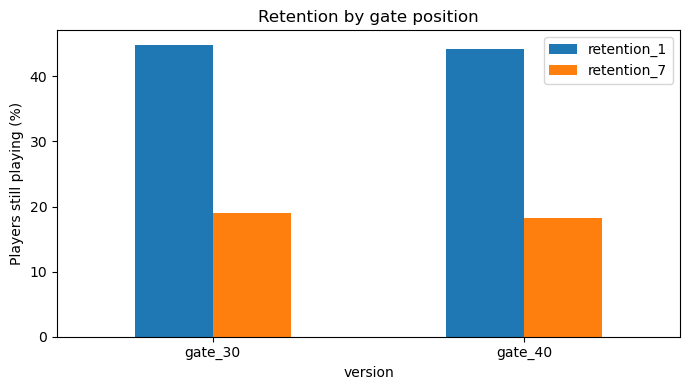

In [5]:
rates = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
rates["players"] = df.groupby("version").size()
print(rates.round(2))
print()
diff = rates.loc["gate_40", ["retention_1", "retention_7"]] - rates.loc["gate_30", ["retention_1", "retention_7"]]
print("Difference, gate_40 minus gate_30 (percentage points):")
print(diff.round(2))

ax = rates[["retention_1", "retention_7"]].plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("Players still playing (%)")
ax.set_title("Retention by gate position")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/retention_by_group.png", dpi=150)
plt.show()

**First look:** Players who met the gate at level 40 came back less often. 1-day retention is 44.82% for gate_30 and 44.23% for gate_40, a drop of 0.59 points. 7-day retention is 19.02% vs 18.20%, a drop of 0.82 points. These are only descriptions. I haven't yet tested whether the gaps could be down to chance.

## A helper that tests one metric

In [6]:
def compare(data, metric):
    s = data.groupby("version")[metric].agg(["sum", "count"])
    c, n = s["sum"].values, s["count"].values      # order: gate_30, gate_40
    _, p = proportions_ztest(c, n)
    lo, hi = confint_proportions_2indep(c[1], n[1], c[0], n[0], compare="diff", alpha=0.05)
    return {
        "metric": metric,
        "gate_30 (%)": c[0] / n[0] * 100,
        "gate_40 (%)": c[1] / n[1] * 100,
        "difference (pp)": (c[1] / n[1] - c[0] / n[0]) * 100,
        "CI low (pp)": lo * 100,
        "CI high (pp)": hi * 100,
        "p-value": p,
    }

## Testing the primary metric: 7-day retention

In [7]:
pd.DataFrame([compare(df, "retention_7")]).T

,0
metric,retention_7
gate_30 (%),19.0201
gate_40 (%),18.2000
difference (pp),-0.8201
CI low (pp),-1.3282
CI high (pp),-0.3121
p-value,0.0016


**Primary result:** For 7-day retention the difference is -0.82 points (19.02% to 18.20%). The 95% confidence interval runs from -1.33 to -0.31 points, so it doesn't include zero, and the p-value is 0.0016. That is well below 0.05, so I reject the idea that both gates keep players equally well. The drop is small in absolute terms, under one point, but it is fairly clear.

## Both metrics, with a stricter cut-off

In [8]:
results = pd.DataFrame([compare(df, "retention_1"), compare(df, "retention_7")])
results["significant at 0.025"] = results["p-value"] < 0.025
results

,metric,gate_30 (%),gate_40 (%),difference (pp),CI low (pp),CI high (pp),p-value,significant at 0.025
0,retention_1,44.8188,44.2283,-0.5905,-1.2392,0.0582,0.0744,False
1,retention_7,19.0201,18.2000,-0.8201,-1.3282,-0.3121,0.0016,True


**Both metrics:** I tested two metrics, so I used a stricter cut-off of 0.025 instead of 0.05. 7-day retention passes (p = 0.0016). 1-day retention doesn't: the difference is -0.59 points, the interval runs from -1.24 to +0.06 and includes zero, and p = 0.0744. So the evidence of a drop is clear at day 7 but not at day 1.

## Robustness checks

In [9]:
df_trim = df[df["sum_gamerounds"] <= cutoff]
print("Players removed:", len(df) - len(df_trim))
pd.DataFrame([compare(df_trim, "retention_1"), compare(df_trim, "retention_7")])

Players removed: 91


,metric,gate_30 (%),gate_40 (%),difference (pp),CI low (pp),CI high (pp),p-value
0,retention_1,44.7704,44.1713,-0.5991,-1.2480,0.0499,0.0704
1,retention_7,18.9458,18.1144,-0.8314,-1.3389,-0.3240,0.0013


**Without the extreme players:** I removed the 91 players above the 99.9th percentile of game rounds. The answer barely moves. 7-day retention still drops by 0.83 points (p = 0.0013), and 1-day retention is still not significant (p = 0.0704). So the extreme players aren't driving the result.

In [10]:
rng = np.random.default_rng(42)
s = df.groupby("version")["retention_7"].agg(["sum", "count"])
p30, p40 = s["sum"] / s["count"]
n30, n40 = s["count"]
draws = rng.binomial(n40, p40, 20000) / n40 - rng.binomial(n30, p30, 20000) / n30
print("95% range from simulation (percentage points):", np.percentile(draws * 100, [2.5, 97.5]).round(2))

95% range from simulation (percentage points): [-1.33 -0.31]


**Simulation check:** A simulation of the 7-day difference gives a 95% range of -1.33 to -0.31 points, essentially the same as the z-test interval. Two different methods agree.

## Was the test big enough?

In [11]:
base = df.loc[df["version"] == "gate_30", "retention_7"].mean()
n_per_group = df.groupby("version").size().min()

for diff in [0.005, 0.01, 0.02]:
    effect = proportion_effectsize(base + diff, base)
    n_needed = NormalIndPower().solve_power(effect_size=effect, power=0.8, alpha=0.05, ratio=1.0)
    print(f"To detect a {diff*100:.1f} percentage-point difference: {n_needed:,.0f} players per group")

h = NormalIndPower().solve_power(effect_size=None, nobs1=n_per_group, power=0.8, alpha=0.05, ratio=1.0)
p2 = np.sin(np.arcsin(np.sqrt(base)) + h / 2) ** 2
print()
print(f"With {n_per_group:,} players per group, the smallest difference we could reliably detect is about {(p2 - base) * 100:.2f} percentage points")

To detect a 0.5 percentage-point difference: 97,679 players per group
To detect a 1.0 percentage-point difference: 24,657 players per group
To detect a 2.0 percentage-point difference: 6,280 players per group

With 44,700 players per group, the smallest difference we could reliably detect is about 0.74 percentage points


**Was the test big enough?** With about 44,700 players per group, the smallest difference I could reliably detect is about 0.74 points. I observed 0.82, which is just above that, so the test could detect an effect this size, but only just. Detecting a 0.5-point difference would need about 97,700 players per group. Because of this, I'm confident about the direction of the drop but less sure about its exact size.

## Game rounds (exploratory only)

In [12]:
print(df.groupby("version")["sum_gamerounds"].agg(["median", "mean"]))
g30 = df.loc[df["version"] == "gate_30", "sum_gamerounds"]
g40 = df.loc[df["version"] == "gate_40", "sum_gamerounds"]
u, p = mannwhitneyu(g30, g40)
print("Mann-Whitney p-value:", round(p, 4))

         median    mean
version                
gate_30 17.0000 52.4563
gate_40 16.0000 51.2988
Mann-Whitney p-value: 0.0502


**Game rounds (exploratory):** The median is 17 rounds for gate_30 and 16 for gate_40, and the means are 52.5 and 51.3. The Mann-Whitney test gives p = 0.0502, just above 0.05. This wasn't one of my planned metrics, so I'm not drawing conclusions from it. Game rounds are also recorded after the gate, so the gate itself may influence them.

## The difference and its uncertainty

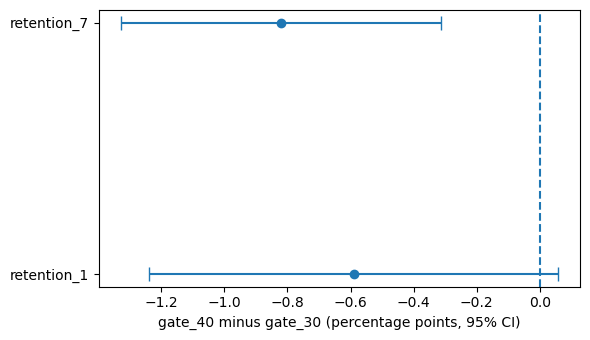

In [13]:
res = results[["metric", "difference (pp)", "CI low (pp)", "CI high (pp)"]]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(res["difference (pp)"], range(len(res)),
            xerr=[res["difference (pp)"] - res["CI low (pp)"], res["CI high (pp)"] - res["difference (pp)"]],
            fmt="o", capsize=5)
ax.axvline(0, linestyle="--")
ax.set_yticks(range(len(res)))
ax.set_yticklabels(res["metric"])
ax.set_xlabel("gate_40 minus gate_30 (percentage points, 95% CI)")
plt.tight_layout()
plt.savefig("outputs/difference_with_ci.png", dpi=150)
plt.show()


**Reading the chart:** The 7-day dot sits to the left of zero and its line doesn't cross zero. The 1-day line does cross zero. That is the main result in one picture.

## Recommendation and limitations

**Decision:** Keep the gate at level 30.

**Why:**
- Primary metric (7-day retention): it fell by 0.82 points when the gate moved to level 40 (19.02% to 18.20%; 95% CI -1.33 to -0.31; p = 0.0016).
- Secondary metric (1-day retention): it fell by 0.59 points but doesn't pass the stricter 0.025 cut-off (p = 0.0744).
- Robustness: the answer didn't change after removing the 91 most active players (-0.83 points, p = 0.0013) or in the simulation.
- Size of the test: the smallest difference I could reliably detect is 0.74 points and I observed 0.82, so the test was only just big enough. The exact size of the drop is uncertain.

**Limitations:**
- Group split: 44,700 vs 45,489 players (p = 0.0086). The groups are slightly uneven, which could hint at an assignment or logging problem. I can't check that with this dataset.
- One game, one change, one period, and no revenue data. A retention gain isn't proven to be a revenue gain, and I can't say why players left.
- Retention is measured at day 1 and day 7 only, so longer-term effects are unknown.
- Game rounds are recorded after the gate, so they are only exploratory.
- I tested two metrics and used a stricter cut-off, but I didn't do any other correction.